# Sarcasm-aware hate speech detection — improved pipeline
Works in **Google Colab**, **Kaggle** and **local Jupyter**. Enable a GPU (Colab: *Runtime → Change runtime type → T4 GPU*; Kaggle: *Settings → Accelerator → GPU* and *Internet → On*).

**What this notebook does**
1. Loads `hatexplain_sarcasm_3199_ai_annotated.csv` (HateXplain posts with **AI-predicted** sarcasm labels), cleans it and uses the train / validation / test split shipped in the file.
2. Trains a **paper-like baseline** (plain BERT) on the same protocol (320 test posts held out, 2559 train, 320 validation).
3. Trains an **improved model**: stronger encoders + multi-task learning (hate/offensive/normal **+ sarcasm detection**; span tagging is switched off because this CSV has no sarcasm spans) + layer-wise LR decay + **gradual layer unfreezing** + label smoothing + class weights, using **K-fold cross-validation** and an **ensemble** of several encoders.
4. Compares against the paper's numbers and your own baseline, with confidence intervals and a significance test.

Rule of thumb: the 320-post **test set is touched only once, at the end**. All tuning uses validation / out-of-fold predictions.

## 1. Setup

In [5]:
import importlib.util
missing = [m for m in ["transformers", "sentencepiece", "tiktoken", "accelerate"] if importlib.util.find_spec(m) is None]
if missing:
    print("installing:", missing, "(needs Internet ON)")
    %pip install -q transformers sentencepiece protobuf tiktoken accelerate
else:
    print("all packages already installed - skipping pip")
# NOTE: model weights (roberta-base, hateBERT, ...) are downloaded from huggingface.co, so Internet must be ON for that too.

all packages already installed - skipping pip


In [6]:
import os, sys, re, gc, json, glob, random, time, difflib, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
warnings.filterwarnings("ignore")

IN_COLAB  = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle/input")
DEVICE    = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "| colab:", IN_COLAB, "| kaggle:", IN_KAGGLE)
if DEVICE.type == "cpu":
    print("WARNING: no GPU found. Training will be extremely slow - enable a GPU runtime.")

# ---------------- configuration ----------------
PRESET = "full"      # "quick": 1 encoder (~10 min) | "full": 4 encoders (~40-60 min) | "large": roberta-large + deberta-v3-large (~1-2 h). Rough times on a T4/P100.
PRESETS = {
    "quick": dict(models=["roberta-base"], folds=5, epochs=8, base_seeds=[1]),
    "full":  dict(models=["roberta-base", "GroNLP/hateBERT", "microsoft/deberta-v3-base", "cardiffnlp/twitter-roberta-base"],
                  folds=5, epochs=8, base_seeds=[1, 2, 3]),
    "large": dict(models=["roberta-large", "microsoft/deberta-v3-large"], folds=5, epochs=6, base_seeds=[1]),
}
LR_BY_MODEL = {"roberta-large": 1.5e-5, "microsoft/deberta-v3-large": 1.5e-5}   # large models need a smaller LR
P = PRESETS[PRESET]
MODELS, FOLDS, EPOCHS, BASE_SEEDS = P["models"], P["folds"], P["epochs"], P["base_seeds"]

SEED, SPLIT_SEED = 42, 42
MAXLEN, BS         = 128, 16
LR, LLRD, HEAD_LR  = 3e-5, 0.95, 2e-4     # base LR, layer-wise LR decay, LR of the new heads
WD, WARMUP, CLIP   = 0.01, 0.1, 1.0
LABEL_SMOOTH       = 0.05
W_SARC, W_TAG      = 0.3, 0.0            # aux sarcasm-detection loss / span-tagging loss (0 = off: this CSV has no sarcasm spans)
PATIENCE           = 3                   # early stopping on validation macro-F1 (only counts once ALL layers are unfrozen)
GRADUAL            = True                # gradual unfreezing: top layers first, then more, then everything
GRAD_STAGES        = 3                   # 12-layer encoder: top 4 -> top 8 -> all 12 (+embeddings) | 24-layer encoder: 8 -> 16 -> 24
GRAD_EPOCHS_PER_STAGE = 1                # epochs spent in each stage before the next block of layers is unfrozen
SAVE_MODELS        = False               # True = keep fold weights (needed for the demo cell at the end; ~0.5 GB each)
USE_DRIVE          = False               # Colab only: store results on Google Drive so a disconnect doesn't lose them

OUT_DIR = "/kaggle/working/runs" if IN_KAGGLE else ("/content/runs" if IN_COLAB else "./runs")
if IN_COLAB and USE_DRIVE:
    from google.colab import drive; drive.mount("/content/drive"); OUT_DIR = "/content/drive/MyDrive/sarcasm_hate_runs"
os.makedirs(OUT_DIR, exist_ok=True)

USE_AMP  = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.get_device_capability()[0] >= 8) else torch.float16
USE_FP16 = USE_AMP and AMP_DTYPE == torch.float16

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
print("models:", MODELS, "| folds:", FOLDS, "| epochs:", EPOCHS, "| amp dtype:", AMP_DTYPE if USE_AMP else None, "| gradual unfreezing:", GRADUAL)

device: cuda | colab: False | kaggle: True
models: ['roberta-base', 'GroNLP/hateBERT', 'microsoft/deberta-v3-base', 'cardiffnlp/twitter-roberta-base'] | folds: 5 | epochs: 8 | amp dtype: torch.float16 | gradual unfreezing: True


## 2. Load the data

In [7]:
def find_data():
    name = "hatexplain_sarcasm_3199_ai_annotated.csv"
    pats = [name, f"../input/**/{name}", f"/kaggle/input/**/{name}", f"/content/**/{name}",
            f"/content/drive/MyDrive/**/{name}", f"/mnt/user-data/uploads/{name}"]
    for p in pats:
        hits = glob.glob(p, recursive=True)
        if hits: return hits[0]
DATA_PATH = find_data()
if DATA_PATH is None and IN_COLAB:
    from google.colab import files
    DATA_PATH = list(files.upload())[0]          # opens an upload dialog
assert DATA_PATH, "CSV not found: put it next to the notebook, add it as a Kaggle dataset, or upload it in Colab."
print("using:", DATA_PATH)

raw = pd.read_csv(DATA_PATH)
print(raw.shape)
print(raw.source_split.value_counts().to_string(), "\n")
print(raw.hate_label.value_counts().to_string(), "\n")
print(pd.crosstab(raw.hate_label, raw.sarcasm_label_ai), "\n")
tox_sarc = ((raw.sarcasm_label_ai == "sarcastic") & raw.hate_label.isin(["hatespeech", "offensive"])).sum()
print(f"sarcastic posts: {(raw.sarcasm_label_ai=='sarcastic').sum()}  | toxic AND sarcastic: {tox_sarc}")
print(f"NOTE: sarcasm labels are AI-predicted ({raw.sarcasm_model_name.iloc[0]}), not human-annotated, so the sarcasm head learns to imitate that model.")
print("mean words/post:", raw.text.str.split().str.len().mean().round(1))

using: ../input/datasets/tanishkavashishth/hatespeech/hatexplain_sarcasm_3199_ai_annotated.csv
(3199, 14)
source_split
train         2559
test           320
validation     320 

hate_label
normal        1279
hatespeech    1012
offensive      908 

sarcasm_label_ai  non_sarcastic  sarcastic
hate_label                                
hatespeech                  458        554
normal                      776        503
offensive                   438        470 

sarcastic posts: 1527  | toxic AND sarcastic: 1024
NOTE: sarcasm labels are AI-predicted (cardiffnlp/twitter-roberta-base-irony), not human-annotated, so the sarcasm head learns to imitate that model.
mean words/post: 23.7


## 3. Cleaning
* `<user>` → `@user`, `<number>` → `number`, etc., so tokenizers don't waste pieces on angle brackets.
* This CSV has **no sarcasm span annotations** (`sarcasm_rationale_token_indices` is empty for every row), so span alignment is skipped: `span` is `None` for all posts and the span-tagging loss is off (`W_TAG = 0`).
* Column names are mapped to what the rest of the notebook uses: `hate_label` → `label`, `sarcasm_label_ai` (`sarcastic` / `non_sarcastic`) → `sarcasm_label` and the 0/1 column `sarcasm`.
* The file has only the 3 classes (no `undecided`) and no duplicate posts, but the duplicate check is kept as a safety net.

In [8]:
LABELS = ["hatespeech", "normal", "offensive"]            # same order as the paper's confusion matrix
L2I = {l: i for i, l in enumerate(LABELS)}

def clean(s):
    s = str(s).replace("\\n", " ")
    s = re.sub(r"<(\w+)>", lambda m: "@user" if m.group(1) == "user" else m.group(1), s)
    return re.sub(r"\s+", " ", s).strip()

df = raw.copy()
df["label"]         = df.hate_label                       # names used by the rest of the notebook
df["sarcasm_label"] = df.sarcasm_label_ai
df["text_clean"]    = df.text.map(clean)
df["y"]             = df.label.map(L2I)
assert df.y.notna().all(), "unexpected hate_label values: " + str(sorted(df.label.unique()))
df["y"]       = df.y.astype(int)
df["sarcasm"] = (df.sarcasm_label_ai == "sarcastic").astype(int)
df["span"]    = None                                      # no sarcasm span annotations in this file
df = df.drop_duplicates("text_clean").reset_index(drop=True)
df["strata"]  = df.label + "_" + df.sarcasm.astype(str)

print(f"posts after cleaning: {len(df)} (raw: {len(raw)}) | sarcastic (AI): {int(df.sarcasm.sum())} | sarcasm spans: none in this file")

posts after cleaning: 3199 (raw: 3199) | sarcastic (AI): 1527 | sarcasm spans: none in this file


## 4. Split (uses the split shipped in the CSV: 2559 train / 320 validation / 320 test)
`labeled` (train + validation) is used for cross-validation; `test` stays untouched until the final evaluation.

In [9]:
labeled = df[df.source_split.isin(["train", "validation"])].reset_index(drop=True)
test    = df[df.source_split == "test"].reset_index(drop=True)
# fixed train/val split for the paper-like baseline = the split given in the file
base_tr = df[df.source_split == "train"].reset_index(drop=True)
base_va = df[df.source_split == "validation"].reset_index(drop=True)
assert len(test) > 0 and len(base_va) > 0 and len(base_tr) > 0, "source_split must contain train / validation / test"
print(f"labeled={len(labeled)}  test={len(test)}  | baseline train={len(base_tr)} val={len(base_va)}")
print(test.label.value_counts().to_dict())

labeled=2879  test=320  | baseline train=2559 val=320
{'hatespeech': 115, 'normal': 115, 'offensive': 90}


## 5. Tokenisation, model and training code

**Gradual unfreezing** (same idea as the RAGF-BERT v5 notebook): the optimizer is built once with *all* parameters, then `requires_grad` is toggled per epoch. Epoch 1 trains only the top 4 encoder layers + the heads, epoch 2 the top 8, epoch 3 onwards everything including the embeddings. Frozen parameters have `grad=None`, so AdamW skips them and keeps their state. For encoders with a different depth the block size is `ceil(n_layers / GRAD_STAGES)`. Early stopping only starts counting once all layers are trainable.

In [10]:
_TOK = {}
def get_tok(name):
    if name not in _TOK: _TOK[name] = AutoTokenizer.from_pretrained(name, use_fast=True)   # fast tokenizer needed for offsets
    return _TOK[name]

def encode(frame, tok):
    # tokenise + build sarcasm-span tag labels (1 = token inside the span, 0 = outside, -100 = ignore)
    items = []
    for r in frame.itertuples():
        enc = tok(r.text_clean, truncation=True, max_length=MAXLEN, return_offsets_mapping=True)
        ids, offs = enc["input_ids"], enc["offset_mapping"]
        tags = [-100] * len(ids)                          # non-sarcastic posts: tagging loss ignored
        if r.span is not None:
            a, b = r.span
            for i, (s, e) in enumerate(offs):
                if e > s: tags[i] = int(s < b and e > a)
        items.append(dict(ids=ids, tags=tags, y=int(r.y), sarc=int(r.sarcasm)))
    return items

def collate(batch, pad_id):
    L = max(len(b["ids"]) for b in batch)
    ids  = torch.tensor([b["ids"]  + [pad_id] * (L - len(b["ids"]))  for b in batch])
    att  = torch.tensor([[1] * len(b["ids"]) + [0] * (L - len(b["ids"])) for b in batch])
    tags = torch.tensor([b["tags"] + [-100]  * (L - len(b["tags"])) for b in batch])
    return dict(input_ids=ids, attention_mask=att, tags=tags,
                labels=torch.tensor([b["y"] for b in batch]), sarcasm=torch.tensor([b["sarc"] for b in batch]))

class MTModel(nn.Module):
    # encoder + 3 heads: hate/offensive/normal, is-sarcastic, sarcasm-span tagging
    def __init__(self, name, pool="cls+mean", dropout=0.1):
        super().__init__()
        self.enc = AutoModel.from_pretrained(name)
        self.enc.float()   # FIX: some checkpoints (e.g. deberta-v3) load in fp16 -> GradScaler crashes ('Attempting to unscale FP16 gradients'). AMP needs fp32 master weights.
        h = self.enc.config.hidden_size
        self.pool, self.drop = pool, nn.Dropout(dropout)
        d = 2 * h if pool == "cls+mean" else h
        self.cls_head, self.sarc_head, self.tag_head = nn.Linear(d, 3), nn.Linear(d, 2), nn.Linear(h, 2)
        self.pad_id = 0
    def head_params(self):
        return list(self.cls_head.parameters()) + list(self.sarc_head.parameters()) + list(self.tag_head.parameters())
    def forward(self, input_ids, attention_mask):
        hs = self.enc(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        if self.pool == "cls+mean":
            m = attention_mask.unsqueeze(-1).to(hs.dtype)
            z = torch.cat([hs[:, 0], (hs * m).sum(1) / m.sum(1).clamp_min(1)], -1)
        else:
            z = hs[:, 0]
        z = self.drop(z)
        return self.cls_head(z), self.sarc_head(z), self.tag_head(self.drop(hs))

def layer_depth(name, n_layers):
    # 0 = embeddings, 1..n = encoder layers (bottom -> top), n = everything else (final norms, pooler)
    m = re.search(r"encoder\.layer\.(\d+)\.", name)
    if m: return int(m.group(1)) + 1
    return 0 if "embeddings" in name else n_layers

def gradual_top_layers(epoch, n_layers, stages=GRAD_STAGES, epochs_per_stage=GRAD_EPOCHS_PER_STAGE):
    # how many of the TOP encoder layers are trainable in this epoch (0-based). 12 layers: 4, 8, 12, 12, ...
    per = -(-n_layers // stages)                              # ceil
    stage = min(epoch // epochs_per_stage, stages - 1)
    return min(n_layers, per * (stage + 1))

def apply_gradual_freeze(model, epoch):
    # toggles requires_grad only (the optimizer is NOT rebuilt). Heads are never frozen.
    n = model.enc.config.num_hidden_layers
    top = gradual_top_layers(epoch, n)
    for name, p in model.enc.named_parameters():
        p.requires_grad_(top >= n or layer_depth(name, n) > n - top)   # embeddings only when ALL layers are trainable
    return top, n

def cv_sig(model_name, lr=None, gradual=None, folds=None):
    # cache key for CV results: changing any of these (incl. the dataset tag 'ai3199' and W_TAG) retrains instead of loading stale folds (gradual runs never overwrite the normal ones)
    lr = LR_BY_MODEL.get(model_name, LR) if lr is None else lr
    gradual = GRADUAL if gradual is None else gradual
    folds = FOLDS if folds is None else folds
    return f"ai3199_k{folds}_e{EPOCHS}_lr{lr}_ll{LLRD}_wt{W_TAG}" + (f"_gu{GRAD_STAGES}x{GRAD_EPOCHS_PER_STAGE}" if gradual else "")

def build_optimizer(model, lr, llrd, head_lr, wd):
    # layer-wise LR decay: top layers learn fastest, embeddings slowest
    n = model.enc.config.num_hidden_layers
    groups = {}
    for name, p in model.enc.named_parameters():
        depth = layer_depth(name, n)
        no_wd = name.endswith("bias") or "LayerNorm" in name or "layer_norm" in name
        groups.setdefault((lr * llrd ** (n - depth), 0.0 if no_wd else wd), []).append(p)
    pg = [dict(params=v, lr=k[0], weight_decay=k[1]) for k, v in groups.items()]
    pg.append(dict(params=model.head_params(), lr=head_lr, weight_decay=wd))
    return torch.optim.AdamW(pg)

def metrics(y, probs):
    pred = probs.argmax(1)
    try: auc = roc_auc_score(y, probs, multi_class="ovr", average="macro")
    except ValueError: auc = float("nan")
    return dict(acc=accuracy_score(y, pred), macro_f1=f1_score(y, pred, average="macro"), auroc=auc)

@torch.no_grad()
def predict_items(model, items, bs=64):
    model.eval(); P, S = [], []
    for i in range(0, len(items), bs):
        b = {k: v.to(DEVICE) for k, v in collate(items[i:i + bs], model.pad_id).items()}
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            lc, ls, _ = model(b["input_ids"], b["attention_mask"])
        P.append(F.softmax(lc.float(), -1).cpu().numpy()); S.append(F.softmax(ls.float(), -1)[:, 1].cpu().numpy())
    return np.concatenate(P), np.concatenate(S)

def train_one(model_name, tr_df, va_df, seed, *, multitask=True, llrd=LLRD, label_smooth=LABEL_SMOOTH, class_w=True,
              pool="cls+mean", lr=LR, head_lr=HEAD_LR, epochs=EPOCHS, bs=BS, verbose=True, w_sarc=W_SARC, w_tag=W_TAG, gradual=False):
    set_seed(seed)
    tok = get_tok(model_name)
    tr_items, va_items = encode(tr_df, tok), encode(va_df, tok)
    model = MTModel(model_name, pool).to(DEVICE); model.pad_id = tok.pad_token_id
    opt = build_optimizer(model, lr, llrd, head_lr, WD)      # holds ALL parameters, so unfreezing later never needs a new optimizer
    n_l, prev_top = model.enc.config.num_hidden_layers, None
    if gradual: assert epochs >= GRAD_STAGES * GRAD_EPOCHS_PER_STAGE, "not enough epochs to finish the unfreezing schedule"
    loader = DataLoader(tr_items, batch_size=bs, shuffle=True, collate_fn=lambda b: collate(b, model.pad_id))
    total = len(loader) * epochs
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP * total), total)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_FP16)
    cw = None
    if class_w:                                   # sqrt-inverse-frequency class weights (helps the small 'offensive' class)
        c = np.bincount(tr_df.y, minlength=3).astype(float); w = (c.sum() / c) ** 0.5
        cw = torch.tensor(w / w.mean(), dtype=torch.float, device=DEVICE)
    best, best_state, bad = -1.0, None, 0
    for ep in range(epochs):
        if gradual: top, _ = apply_gradual_freeze(model, ep)   # epoch 1: top 4 layers, epoch 2: top 8, epoch 3+: all layers + embeddings
        else:       top = n_l
        if verbose and gradual and top != prev_top:
            n_tr = sum(p.numel() for p in model.enc.parameters() if p.requires_grad) / 1e6
            print(f"  [gradual unfreezing] epoch {ep+1}: top {top}/{n_l} layers trainable ({n_tr:.0f}M encoder params)")
        prev_top = top
        model.train(); tot, nb_ = 0.0, 0
        for b in loader:
            b = {k: v.to(DEVICE) for k, v in b.items()}
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                lc, ls, lt = model(b["input_ids"], b["attention_mask"])
            loss = F.cross_entropy(lc.float(), b["labels"], weight=cw, label_smoothing=label_smooth)
            if multitask:
                loss = loss + w_sarc * F.cross_entropy(ls.float(), b["sarcasm"])
                if w_tag > 0 and (b["tags"] != -100).any():
                    loss = loss + w_tag * F.cross_entropy(lt.float().view(-1, 2), b["tags"].view(-1), ignore_index=-100)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), CLIP)
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item(); nb_ += 1
        pv, _ = predict_items(model, va_items)
        f1 = f1_score(va_df.y, pv.argmax(1), average="macro")
        if verbose: print(f"  epoch {ep+1}/{epochs} | mean train loss {tot/nb_:.3f} | val macro-F1 {f1:.4f}")
        if f1 > best:
            best, bad = f1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            if top >= n_l: bad += 1                      # patience only counts once every layer is trainable
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    return model, best

def free(*objs):
    for o in objs: del o
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

## 6. Paper-like baseline (plain BERT, same protocol)
Plain `bert-base-uncased`, `[CLS]` pooling, lr 2e-5, no auxiliary tasks, no label smoothing or class weights. This is **your own reference point on your own test set**, which is the fair comparison, because the paper's test set is not public.

In [11]:
BASE = {}
t0 = time.time()
for s in BASE_SEEDS:
    print(f"baseline seed {s}")
    m, bf1 = train_one("bert-base-uncased", base_tr, base_va, seed=s, multitask=False, llrd=1.0, label_smooth=0.0,
                       class_w=False, pool="cls", lr=2e-5, head_lr=2e-5, epochs=5)
    p, _ = predict_items(m, encode(test, get_tok("bert-base-uncased")))
    BASE[s] = p; free(m)
    print("  test:", {k: round(v, 4) for k, v in metrics(test.y.values, p).items()})
base_rows = [metrics(test.y.values, p) for p in BASE.values()]
base_mean = {k: float(np.mean([r[k] for r in base_rows])) for k in base_rows[0]}
print("baseline mean over seeds:", {k: round(v, 4) for k, v in base_mean.items()}, f"| {time.time()-t0:.0f}s")

baseline seed 1


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

... (6 outputs left out)

  epoch 1/5 | mean train loss 1.004 | val macro-F1 0.6465
  epoch 2/5 | mean train loss 0.728 | val macro-F1 0.6696
  epoch 3/5 | mean train loss 0.527 | val macro-F1 0.6628
  epoch 4/5 | mean train loss 0.353 | val macro-F1 0.6684
  epoch 5/5 | mean train loss 0.245 | val macro-F1 0.6610
  test: {'acc': 0.6719, 'macro_f1': 0.655, 'auroc': np.float64(0.8352)}
baseline seed 3


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  epoch 1/5 | mean train loss 1.000 | val macro-F1 0.6853
  epoch 2/5 | mean train loss 0.738 | val macro-F1 0.7016
  epoch 3/5 | mean train loss 0.531 | val macro-F1 0.6926
  epoch 4/5 | mean train loss 0.361 | val macro-F1 0.6873
  epoch 5/5 | mean train loss 0.250 | val macro-F1 0.6964
  test: {'acc': 0.6781, 'macro_f1': 0.6651, 'auroc': np.float64(0.836)}
baseline mean over seeds: {'acc': 0.6698, 'macro_f1': 0.6556, 'auroc': 0.8356} | 237s


## 7. Improved model: K-fold CV, multi-task, several encoders
Each encoder is trained **K times** on different train/validation folds of `labeled`. Every fold model predicts the test set (averaged), and every post in `labeled` gets one **out-of-fold** prediction, which gives a trustworthy accuracy estimate on ~2.9k posts instead of only 300.
Results are cached in `OUT_DIR`, so if Colab disconnects you can re-run the cell and it resumes.

In [12]:
def run_cv(model_name, **kw):
    tag = re.sub(r"[^A-Za-z0-9]+", "_", model_name)
    kw.setdefault("lr", LR_BY_MODEL.get(model_name, LR))
    kw.setdefault("gradual", GRADUAL)
    sig = cv_sig(model_name, kw["lr"], kw["gradual"])      # cache key: changing any of these retrains
    tok = get_tok(model_name); te_items = encode(test, tok)
    oof = np.zeros((len(labeled), 3)); test_p = []
    skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SPLIT_SEED)
    for f, (a, b) in enumerate(skf.split(labeled, labeled.strata)):
        cache = f"{OUT_DIR}/{tag}_{sig}_fold{f}.npz"
        if os.path.exists(cache):
            z = np.load(cache); oof[b] = z["oof"]; test_p.append(z["test"]); print(f"[{tag}] fold {f}: loaded from cache"); continue
        print(f"[{tag}] fold {f+1}/{FOLDS}")
        model, best = train_one(model_name, labeled.iloc[a].reset_index(drop=True), labeled.iloc[b].reset_index(drop=True),
                                seed=SEED + f, **kw)
        ob, _ = predict_items(model, encode(labeled.iloc[b].reset_index(drop=True), tok))
        tp, _ = predict_items(model, te_items)
        np.savez(cache, oof=ob, test=tp); oof[b] = ob; test_p.append(tp)
        if SAVE_MODELS: torch.save(model.state_dict(), f"{OUT_DIR}/{tag}_{sig}_fold{f}.pt")
        free(model)
    return dict(oof=oof, test=np.mean(test_p, 0))

CV, t0 = {}, time.time()
for name in MODELS:
    try:
        CV[name] = run_cv(name)
        print(f"==> {name}: OOF", {k: round(v, 4) for k, v in metrics(labeled.y.values, CV[name]["oof"]).items()},
              f"| {time.time()-t0:.0f}s elapsed")
    except Exception as e:                      # e.g. no internet / model name unavailable: skip it, keep going
        print(f"!! skipped {name}: {type(e).__name__}: {str(e)[:150]}")
assert CV, "no model trained successfully"

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[roberta_base] fold 1/5


... (82 outputs left out)

  [gradual unfreezing] epoch 1: top 4/12 layers trainable (29M encoder params)
  epoch 1/8 | mean train loss 1.231 | val macro-F1 0.5650
  [gradual unfreezing] epoch 2: top 8/12 layers trainable (57M encoder params)
  epoch 2/8 | mean train loss 0.949 | val macro-F1 0.6312
  [gradual unfreezing] epoch 3: top 12/12 layers trainable (125M encoder params)
  epoch 3/8 | mean train loss 0.741 | val macro-F1 0.6438
  epoch 4/8 | mean train loss 0.543 | val macro-F1 0.6432
  epoch 5/8 | mean train loss 0.366 | val macro-F1 0.6443
  epoch 6/8 | mean train loss 0.271 | val macro-F1 0.6458
  epoch 7/8 | mean train loss 0.231 | val macro-F1 0.6493
  epoch 8/8 | mean train loss 0.213 | val macro-F1 0.6496
[cardiffnlp_twitter_roberta_base] fold 5/5


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: cardiffnlp/twitter-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.decoder.bias      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [gradual unfreezing] epoch 1: top 4/12 layers trainable (29M encoder params)
  epoch 1/8 | mean train loss 1.248 | val macro-F1 0.5346
  [gradual unfreezing] epoch 2: top 8/12 layers trainable (57M encoder params)
  epoch 2/8 | mean train loss 0.962 | val macro-F1 0.6304
  [gradual unfreezing] epoch 3: top 12/12 layers trainable (125M encoder params)
  epoch 3/8 | mean train loss 0.756 | val macro-F1 0.6624
  epoch 4/8 | mean train loss 0.528 | val macro-F1 0.6479
  epoch 5/8 | mean train loss 0.362 | val macro-F1 0.6472
  epoch 6/8 | mean train loss 0.272 | val macro-F1 0.6343
==> cardiffnlp/twitter-roberta-base: OOF {'acc': 0.6652, 'macro_f1': 0.6573, 'auroc': np.float64(0.8173)} | 2180s elapsed


## 8. Ensemble + calibration on out-of-fold predictions
* The ensemble averages probabilities across encoders.
* "Calibration" rescales the 'offensive' probability (the hardest class) to maximise macro-F1 on the **out-of-fold** predictions (never on test). It is only applied if it helps by more than 0.005, to avoid overfitting.

In [13]:
y_lab, y_te = labeled.y.values, test.y.values
oof_ens  = np.mean([v["oof"]  for v in CV.values()], 0)
test_ens = np.mean([v["test"] for v in CV.values()], 0)
print("OOF macro-F1 per model :", {k: round(metrics(y_lab, v["oof"])["macro_f1"], 4) for k, v in CV.items()})
print("OOF macro-F1 ensemble  :", round(metrics(y_lab, oof_ens)["macro_f1"], 4))

def tune_class_weights(probs, y, grid=np.arange(0.8, 2.01, 0.1)):
    # only ONE free parameter (a multiplier for the hard 'offensive' class) so it cannot overfit much
    base = f1_score(y, probs.argmax(1), average="macro"); best = (base, 1.0)
    for w2 in grid:
        f = f1_score(y, (probs * np.array([1.0, 1.0, w2])).argmax(1), average="macro")
        if f > best[0] + 1e-9: best = (f, w2)
    return (np.array([1.0, 1.0, best[1]]), best[0]) if best[0] - base > 0.005 else (np.ones(3), base)

W_CAL, f_cal = tune_class_weights(oof_ens, y_lab)
print("class weights (hate, normal, offensive):", np.round(W_CAL, 2), "| OOF macro-F1 after calibration:", round(f_cal, 4))
test_cal = test_ens * W_CAL
test_cal = test_cal / test_cal.sum(1, keepdims=True)

OOF macro-F1 per model : {'roberta-base': 0.6595, 'GroNLP/hateBERT': 0.6546, 'microsoft/deberta-v3-base': 0.6572, 'cardiffnlp/twitter-roberta-base': 0.6573}
OOF macro-F1 ensemble  : 0.6803
class weights (hate, normal, offensive): [1. 1. 1.] | OOF macro-F1 after calibration: 0.6803


## 9. Final evaluation on the held-out test set (run once)

In [14]:
GU = " + gradual unfreezing" if GRADUAL else ""
PAPER = {"Paper baseline (their test set)": dict(acc=0.7425, macro_f1=0.6883, auroc=0.8264),
         "Paper proposed (their test set)": dict(acc=0.7492, macro_f1=0.6983, auroc=0.8450)}
best_single = max(CV, key=lambda k: metrics(y_lab, CV[k]["oof"])["macro_f1"])      # chosen by OOF, not by test
rows = dict(PAPER)
rows["Ours: BERT baseline (mean of seeds)"] = base_mean
rows[f"Ours: best single ({best_single}){GU}"]  = metrics(y_te, CV[best_single]["test"])
rows[f"Ours: ensemble{GU}"]                     = metrics(y_te, test_ens)
rows[f"Ours: ensemble + calibration{GU}"]       = metrics(y_te, test_cal)
rows[f"Ours: ensemble OOF (n={len(labeled)}, most reliable){GU}"] = metrics(y_lab, oof_ens)
tab = pd.DataFrame(rows).T.round(4); print(tab.to_string())

final = test_cal if f_cal > metrics(y_lab, oof_ens)["macro_f1"] else test_ens
pred_f, pred_b = final.argmax(1), BASE[BASE_SEEDS[0]].argmax(1)
print("\nfinal model :", {k: round(v, 4) for k, v in metrics(y_te, final).items()})

# ---- uncertainty: 320 test posts => ~ +-2.5 points, so always look at the CI ----
rng = np.random.default_rng(0); acc_b, f1_b = [], []
for _ in range(2000):
    i = rng.integers(0, len(y_te), len(y_te))
    acc_b.append((pred_f[i] == y_te[i]).mean()); f1_b.append(f1_score(y_te[i], pred_f[i], average="macro"))
print(f"accuracy 95% CI : [{np.percentile(acc_b, 2.5):.3f}, {np.percentile(acc_b, 97.5):.3f}]")
print(f"macro-F1 95% CI : [{np.percentile(f1_b, 2.5):.3f}, {np.percentile(f1_b, 97.5):.3f}]")

# ---- paired significance vs. your own baseline (McNemar exact test) ----
from scipy.stats import binomtest
cf, cb = pred_f == y_te, pred_b == y_te
a_only, b_only = int((cf & ~cb).sum()), int((cb & ~cf).sum())
pv = binomtest(min(a_only, b_only), a_only + b_only, 0.5).pvalue if a_only + b_only else 1.0
print(f"vs baseline: final-only correct={a_only}, baseline-only correct={b_only}, McNemar p={pv:.4f}")

                                                                    acc  macro_f1   auroc
Paper baseline (their test set)                                  0.7425    0.6883  0.8264
Paper proposed (their test set)                                  0.7492    0.6983  0.8450
Ours: BERT baseline (mean of seeds)                              0.6698    0.6556  0.8356
Ours: best single (roberta-base) + gradual unfreezing            0.6625    0.6504  0.8239
Ours: ensemble + gradual unfreezing                              0.6656    0.6576  0.8359
Ours: ensemble + calibration + gradual unfreezing                0.6656    0.6576  0.8359
Ours: ensemble OOF (n=2879, most reliable) + gradual unfreezing  0.6874    0.6803  0.8458

final model : {'acc': 0.6656, 'macro_f1': 0.6576, 'auroc': np.float64(0.8359)}
accuracy 95% CI : [0.613, 0.716]
macro-F1 95% CI : [0.605, 0.705]
vs baseline: final-only correct=33, baseline-only correct=31, McNemar p=0.9007


              precision    recall  f1-score   support

  hatespeech      0.784     0.757     0.770       115
      normal      0.700     0.670     0.684       115
   offensive      0.495     0.544     0.519        90

    accuracy                          0.666       320
   macro avg      0.660     0.657     0.658       320
weighted avg      0.672     0.666     0.668       320

accuracy on SARCASTIC test posts (n=157): final=0.643  baseline=0.618
accuracy on NON-sarcastic posts (n=163): final=0.687  baseline=0.699
OOF accuracy (n=2879): sarcastic posts (n=1370) = 0.648 | non-sarcastic = 0.723


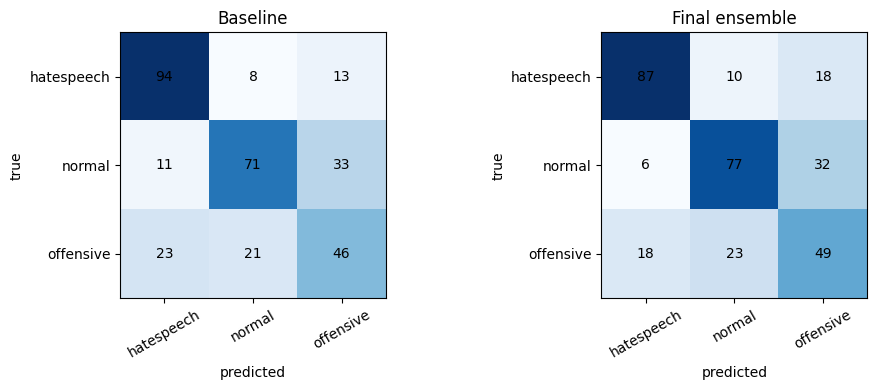

saved -> /kaggle/working/runs


In [15]:
import matplotlib.pyplot as plt
print(classification_report(y_te, pred_f, target_names=LABELS, digits=3))

# the paper's actual goal: hate hidden in sarcasm -> look at the sarcastic subset separately
sm = test.sarcasm.values == 1
print(f"accuracy on SARCASTIC test posts (n={sm.sum()}): final={cf[sm].mean():.3f}  baseline={cb[sm].mean():.3f}")
print(f"accuracy on NON-sarcastic posts (n={(~sm).sum()}): final={cf[~sm].mean():.3f}  baseline={cb[~sm].mean():.3f}")
sm_l = labeled.sarcasm.values == 1; pl = oof_ens.argmax(1)
print(f"OOF accuracy (n={len(labeled)}): sarcastic posts (n={sm_l.sum()}) = {(pl[sm_l]==y_lab[sm_l]).mean():.3f} | non-sarcastic = {(pl[~sm_l]==y_lab[~sm_l]).mean():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, pr) in zip(ax, [("Baseline", pred_b), ("Final ensemble", pred_f)]):
    cm = confusion_matrix(y_te, pr); a.imshow(cm, cmap="Blues")
    a.set_xticks(range(3)); a.set_yticks(range(3)); a.set_xticklabels(LABELS, rotation=30); a.set_yticklabels(LABELS)
    for i in range(3):
        for j in range(3): a.text(j, i, cm[i, j], ha="center", va="center", color="black")
    a.set_title(name); a.set_xlabel("predicted"); a.set_ylabel("true")
plt.tight_layout(); plt.show()

out = test[["post_id", "text", "label", "sarcasm_label"]].copy()
out["pred"] = [LABELS[i] for i in pred_f]
for i, l in enumerate(LABELS): out[f"p_{l}"] = final[:, i].round(4)
out.to_csv(f"{OUT_DIR}/test_predictions.csv", index=False); tab.to_csv(f"{OUT_DIR}/results_table.csv")
print("saved ->", OUT_DIR)

## 10. Error analysis
Look at confidently-wrong posts: these show what the model still misses (often genuinely ambiguous labels in HateXplain).

In [16]:
err = out[out.label != out.pred].copy()
err["conf"] = final[(out.label != out.pred).values].max(1)
pd.set_option("display.max_colwidth", 140)
print(f"{len(err)} errors out of {len(out)}")
err.sort_values("conf", ascending=False)[["text", "label", "pred", "sarcasm_label", "conf"]].head(12)

107 errors out of 320


,text,label,pred,sarcasm_label,conf
74,there are good and decent people here who have no interest in hearing jew nigger kike spic jap wop dago mick kraut porch monkey sand nig...,normal,hatespeech,non_sarcastic,0.975616
266,shut this billionaire bugatti brick this nigger pole,normal,hatespeech,non_sarcastic,0.964555
65,looking at all this nigger ruin wondering when we starting spelling detroit with a z,offensive,hatespeech,sarcastic,0.932913
133,<user> puppy no i was alone i am not a nazi white supremacist or any other type of person i am <number> southern i support traditional v...,offensive,normal,non_sarcastic,0.927549
295,ancient made up european gods and ancient made up kike gods are the exact same thing if you are not worshiping actual god you are worshi...,offensive,hatespeech,non_sarcastic,0.926378
7,also in this same vibe any wigger who calls white missionaries who save the lives of non white children in africa india ect a race trait...,offensive,hatespeech,sarcastic,0.926232
289,ooh my car so retarded this bitch just farted,normal,offensive,non_sarcastic,0.916676
121,i mean of course we do not know why he did it we have yet to establish a clear motive it may just have been a sexualemergency hence his ...,offensive,normal,non_sarcastic,0.903781
52,<user> normalize hating white people,offensive,normal,sarcastic,0.864453
126,kevin spacey raped me by making me watch all the way through that queer man fantasia american beauty in the hope of seeing mena suvari t...,offensive,normal,sarcastic,0.850102


## 11. Ablation: what actually helps? (does modelling sarcasm help?)
Four variants of the same encoder (`MODELS[0]`), each scored by **out-of-fold** predictions over all labelled posts (never the test set), repeated with several seeds. Look at `oof_macro_f1` (overall) and `acc_on_sarcastic` (posts the AI model labelled sarcastic). Compare variant 2 vs 3 to isolate the effect of the sarcasm head, and variant 3 vs 4 to isolate gradual unfreezing. The old span-tagging variant is removed because this CSV has no sarcasm spans. Because the sarcasm labels are AI-predicted, a gain from the sarcasm head means 'imitating that irony model helps', not 'human-annotated sarcasm helps'.

In [17]:
RUN_ABLATION, ABL_SEEDS, ABL_FOLDS = True, [1, 2], 3      # ~30-50 min; set False to skip

def cv_oof(name, kw, seed0):
    oof = np.zeros((len(labeled), 3)); tok = get_tok(name)
    skf = StratifiedKFold(ABL_FOLDS, shuffle=True, random_state=SPLIT_SEED)
    for f, (a, b) in enumerate(skf.split(labeled, labeled.strata)):
        tr_f, va_f = labeled.iloc[a].reset_index(drop=True), labeled.iloc[b].reset_index(drop=True)
        m, _ = train_one(name, tr_f, va_f, seed=seed0 + f, verbose=False, **kw)
        oof[b] = predict_items(m, encode(va_f, tok))[0]; free(m)
    return oof

if RUN_ABLATION:
    name = MODELS[0]; yl = labeled.y.values; sm = labeled.sarcasm.values == 1
    lr0 = LR_BY_MODEL.get(name, LR)
    variants = {
        "1 plain (paper-like: CLS, no tricks)":   dict(multitask=False, llrd=1.0, label_smooth=0.0, class_w=False, pool="cls", lr=2e-5, head_lr=2e-5),
        "2 + tricks (LLRD, smoothing, weights)":  dict(multitask=False, lr=lr0),
        "3 + sarcasm head":                       dict(multitask=True, w_tag=0.0, lr=lr0),
        "4 + sarcasm head + gradual unfreezing":  dict(multitask=True, w_tag=0.0, lr=lr0, gradual=True),
    }
    rows = []
    for vname, kw in variants.items():
        f1s, accs, allacc = [], [], []
        for s in ABL_SEEDS:
            p = cv_oof(name, kw, 100 * s).argmax(1)
            f1s.append(f1_score(yl, p, average="macro")); allacc.append((p == yl).mean()); accs.append((p[sm] == yl[sm]).mean())
        rows.append(dict(variant=vname, oof_macro_f1=np.mean(f1s), f1_std=np.std(f1s), oof_acc=np.mean(allacc), acc_on_sarcastic=np.mean(accs)))
        print(rows[-1])
    print(); print(pd.DataFrame(rows).round(4).to_string(index=False))
    print("\nRule of thumb: a difference smaller than ~2x f1_std is not trustworthy.")


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (42 outputs left out)

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'variant': '4 + sarcasm head + gradual unfreezing', 'oof_macro_f1': np.float64(0.6452292311490055), 'f1_std': np.float64(0.002242010031219155), 'oof_acc': np.float64(0.6535255296978117), 'acc_on_sarcastic': np.float64(0.6266423357664234)}

                              variant  oof_macro_f1  f1_std  oof_acc  acc_on_sarcastic
 1 plain (paper-like: CLS, no tricks)        0.6447  0.0004   0.6537            0.6245
2 + tricks (LLRD, smoothing, weights)        0.6450  0.0046   0.6506            0.6223
                     3 + sarcasm head        0.6475  0.0047   0.6509            0.6153
4 + sarcasm head + gradual unfreezing        0.6452  0.0022   0.6535            0.6266

Rule of thumb: a difference smaller than ~2x f1_std is not trustworthy.


## 12. (Optional) Demo: classify new text
Needs `SAVE_MODELS = True` before running section 7 (or load fold weights you saved). Uses the fold models of one encoder.

In [18]:
def predict_texts(texts, model_name=None, folds=FOLDS):
    model_name = model_name or MODELS[0]; tag = re.sub(r"[^A-Za-z0-9]+", "_", model_name); tok = get_tok(model_name)
    fr = pd.DataFrame(dict(text_clean=[clean(t) for t in texts], y=0, sarcasm=0, span=[None] * len(texts)))
    items, probs = encode(fr, tok), []
    sig = cv_sig(model_name, LR_BY_MODEL.get(model_name, LR), GRADUAL, folds)
    for f in range(folds):
        path = f"{OUT_DIR}/{tag}_{sig}_fold{f}.pt"
        if not os.path.exists(path): continue
        m = MTModel(model_name).to(DEVICE); m.load_state_dict(torch.load(path, map_location=DEVICE)); m.pad_id = tok.pad_token_id
        probs.append(predict_items(m, items)[0]); free(m)
    assert probs, "No saved weights found - set SAVE_MODELS=True and re-run section 7."
    P = np.mean(probs, 0)
    return [(LABELS[i], round(float(p[i]), 3)) for p, i in zip(P, P.argmax(1))]

if SAVE_MODELS:
    print(predict_texts(["have a lovely day everyone", "oh sure, because THAT group is always so peaceful"]))